In [25]:
# notebooks/result_processing.ipynb

# ---
# # Experiment Results Analysis
# This notebook orchestrates the loading, analysis, and reporting of experiment
# results logged to Weights & Biases.
# ---

# ## 1. Setup and Imports
# Import necessary libraries and custom modules. The `sys.path.append` line
# allows the notebook to find the custom `picid_report` package.
import sys
import pandas as pd
sys.path.append('..')

from picid_report.core import load_runs_df
from picid_report.core import analyze_results
from picid_report.report import create_summary_table

import seaborn as sns

%load_ext autoreload
%autoreload 2

# ---
# ## 2. Configuration
# Define all key parameters for the analysis in one place.
# ---



# PROJECT_NAME = "xjtu_sy_full"
# PROJECT_NAME = "nb14_full"
# PROJECT_NAME = "unibo_full"
PROJECT_NAME = "n_cmapss_scaling"
PROJECT_NAME = "16_02_2026_scaling_phme20_prognostics_raw"
PROJECT_NAME = "16_02_2026_scaling_blockwise_new_evaluator_phme20_prognostics_raw"
PROJECT_NAME = "16_02_2026_scaling_blockwise_phme20_prognostics_raw"


PROJECT_NAME = "16_04_2026_scaling_mzvav_diagnostics_"
PROJECT_NAME = "16_04_2026_scaling_blockwise_unibo_prognostics_combined"
PROJECT_NAME = "16_04_2026_scaling_concepts_n_cmapss_ds02_prognostics_"
PROJECT_NAME = "16_04_2026_scaling_blockwise_concepts_n_cmapss_ds02_prognostics_"

# PROJECT_NAME = "n_cmapss_final"
# PROJECT_NAME = "TabPFN_ds02_sweep_2025_10_09"
# PROJECT_NAME = "railway_traction_final"
# PROJECT_NAME = "phme20_full"
USER = "imos-buildingenergy-1"

METRIC_PREFIXES = [
    # "val/", 
    "test/"
]
REPORTING_METRICS = [
    # "loss", 
    "mse", 
    "mae", 
    "rmse",
    "mse_normalized",
    "mae_normalized",
    "rmse_normalized",
    "mse_denormalized",
    "mae_denormalized",
    "rmse_denormalized",
]


REPORTING_METRICS_BATTERY =  [f"{r}_mean" for r in REPORTING_METRICS] + ["phme_score_mean"]




# Configure pandas display options for better readability in the notebook.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# ---
# ## 3. Data Loading
# Fetch data from wandb (or a local cache) and prepare the initial DataFrame.
# The `load_runs_df` function handles all the complex cleaning and flattening.
# ---
df, config_columns, dropped_columns = load_runs_df(
    project_name=PROJECT_NAME, 
    user=USER
)

# ---
# ## 4. Core Analysis
# Run the main analysis function to group results by dataset and model,
# find the best hyperparameter configuration, and collect performance metrics.
# ---

if "nb14" in PROJECT_NAME or "unibo" in PROJECT_NAME:


    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS_BATTERY,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_mean",
        optimization_mode="min"
    )
    
elif "n_cmapss" in PROJECT_NAME:
    
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_denormalized",
        optimization_mode="min"
    )
    
else:
    
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_normalized",
        optimization_mode="min"
    )

# ---
# ## 5. Generate and Display Summary
# Create the final pivoted summary table for a high-level overview
# of the best performance for each model on each dataset.
# ---
summary_df = create_summary_table(all_results, precision=3)
summary_df.index = summary_df.index.str.split(".").str[-1].str.replace("_", "-")  # Simplify model names

print("\n📊 Final Performance Summary Table:")
display(summary_df)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Load: project=16_04_2026_scaling_blockwise_concepts_n_cmapss_ds02_prognostics_, user=imos-buildingenergy-1, cache_dir=csv_files
Fetching runs from wandb project: imos-buildingenergy-1/16_04_2026_scaling_blockwise_concepts_n_cmapss_ds02_prognostics_...


  0%|          | 0/156 [00:00<?, ?it/s]

Skipping run '0.4+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_7f7ad1d2' with state 'failed'
Skipping run '0.5+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_35b65e1a' with state 'failed'
Skipping run '0.6+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_8799494d' with state 'failed'
Skipping run '0.7+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_5abf9eaa' with state 'failed'
Skipping run '0.8+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_c92bf95d' with state 'failed'
Skipping run '0.9+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_699a5fc5' with state 'failed'
Skipping run '1.0+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_790447e9' with state 'failed'
Skipping run '0.4+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_6cb727ee' with state 'failed'
Skipping run '0.5+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_f7b33cc8' with state 'failed'


 33%|███▎      | 51/156 [00:00<00:00, 117.97it/s]

Skipping run '0.6+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_c76bae02' with state 'failed'
Skipping run '0.7+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_dbf2da5e' with state 'failed'
Skipping run '0.8+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_d13c9b36' with state 'failed'
Skipping run '0.9+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_aa6f7034' with state 'failed'
Skipping run '1.0+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_76f9c7e2' with state 'failed'
Skipping run '0.4+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_01112f55' with state 'failed'
Skipping run '0.5+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_b3469c09' with state 'failed'
Skipping run '0.6+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_0d864903' with state 'failed'
Skipping run '0.7+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_f6876518' with state 'failed'
Skipping run '0.8+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_dcd568b0' 

...

 97%|█████████▋| 151/156 [00:00<00:00, 165.18it/s]

Skipping run '0.6+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_cdaf07d1' with state 'failed'
Skipping run '0.7+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_25b768cb' with state 'failed'
Skipping run '0.8+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_64b2a73d' with state 'failed'
Skipping run '0.9+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_893ed26b' with state 'failed'
Skipping run '1.0+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_4939a6ff' with state 'failed'


100%|██████████| 156/156 [00:00<00:00, 157.16it/s]

Saved 84 runs to cache: csv_files/16_04_2026_scaling_blockwise_concepts_n_cmapss_ds02_prognostics_.csv
Dropped 23 columns with >90% NaN
Dropped 60 columns by name filters
Analyze: 1 dataset(s), 2 model(s) -> 2 (dataset, model) combinations
  MultiSource_concepts_N-CMAPSS | picid.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper: opt=test/mae_denormalized mode=min grid=auto sort=test/mae_denormalized runs=28 configs_failed_seed=0 configs_failed_invalid_metric=0
  MultiSource_concepts_N-CMAPSS | picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper: opt=test/mae_denormalized mode=min grid=auto sort=test/mae_denormalized runs=56 configs_failed_seed=0 configs_failed_invalid_metric=0

📊 Final Performance Summary Table:


Dataset                 MultiSource_concepts_N-CMAPSS                                                                                                                                                 \
Metric                                      test/loss test/mae_denormalized  test/mae_normalized  test/mse_denormalized  test/mse_normalized test/nasa_score_denormalized test/nasa_score_normalized   
Model                                                                                                                                                                                                  
FitPredictTabDPTWrapper           1.000 ± 0.000 (n=4)   5.683 ± 0.216 (n=4)  0.057 ± 0.002 (n=4)   64.057 ± 4.551 (n=4)  0.006 ± 0.000 (n=4)          1.105 ± 0.076 (n=4)        0.005 ± 0.000 (n=4)   
FitPredictTabPFNWrapper           1.000 ± 0.000 (n=4)   5.962 ± 1.779 (n=4)  0.060 ± 0.018 (n=4)  64.870 ± 33.893 (n=4)  0.006 ± 0.003 (n=4)          1.099 ± 0.612 (n=4)        0.006 ± 0.002 (n=4)   

Dataset                                                              
Metric                  test/rmse_denormalized test/rmse_normalized  
Model                                                                
FitPredictTabDPTWrapper    8.000 ± 0.284 (n=4)  0.080 ± 0.003 (n=4)  
FitPredictTabPFNWrapper    7.870 ± 1.978 (n=4)  0.079 ± 0.020 (n=4)

In [7]:
print(summary_df.to_latex())

\begin{tabular}{llllllllllllllllll}
\toprule
Dataset & \multicolumn{17}{r}{UNIBO21} \\
Metric & test/loss & test/mae_denormalized & test/mae_denormalized_mean & test/mae_normalized & test/mae_normalized_mean & test/mse_denormalized & test/mse_denormalized_mean & test/mse_normalized & test/mse_normalized_mean & test/phm_score_denormalized & test/phm_score_denormalized_mean & test/phm_score_normalized & test/phm_score_normalized_mean & test/rmse_denormalized & test/rmse_denormalized_mean & test/rmse_normalized & test/rmse_normalized_mean \\
Model &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
FitPredictTabDPTWrapper & 1.000 ± 0.000 (n=5) & 146.491 ± 6.911 (n=5) & 139.669 ± 6.476 (n=5) & 0.298 ± 0.014 (n=5) & 0.284 ± 0.013 (n=5) & 25434.541 ± 2427.100 (n=5) & 22987.605 ± 2064.095 (n=5) & 0.105 ± 0.010 (n=5) & 0.095 ± 0.009 (n=5) & 0.085 ± 0.003 (n=5) & 0.065 ± 0.003 (n=5) & 0.085 ± 0.003 (n=5) & 0.065 ± 0.003 (n=5) & 159.340 ± 7.536 (n=5) & 150.216 ± 6.616 (n=5) & 0.324 ± 

For MZVAV

In [8]:
df_long = df[[
    "test/f1", 
    "model._target_", 
    "seed", 
    "task_definition.subset_ratio", 
    "task_definition.seq_len"]]
df_long
# df_long["ds"] = df["datasource.multisource_data_splitter.sources_train"].astype(str) 

df_long = df_long.melt(
    id_vars=[
        "model._target_",
        "seed",
        "task_definition.subset_ratio",
        "task_definition.seq_len",
        # "ds"
    ],
    value_vars=["test/f1"],
    var_name="metric",
    value_name="value"
)
df_long


df_long = df_long[~((df_long["model._target_"] == "picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper") & (df_long["task_definition.seq_len"] == 5))]
df_long.head()

KeyError: "['test/f1'] not in index"

For N-CMAPSS:

In [3]:
conflicts = df["test/mae"].notna() & df["test/mae_normalized"].notna()
print(conflicts.any(), df[conflicts].shape[0])

df["test/mae_normalized"] = df["test/mae_normalized"].combine_first(df["test/mae"])
df["test/rmse_normalized"] = df["test/rmse_normalized"].combine_first(df["test/rmse"])
df["test/mae_denormalized"] = df["test/mae_denormalized"].combine_first(df["test/mae"])
df["test/rmse_denormalized"] = df["test/rmse_denormalized"].combine_first(df["test/rmse"])

KeyError: 'test/mae'

For PHME20:

In [26]:

df_long = df[[
    "test/mae_normalized", 
    "test/rmse_normalized",
    "test/mae_denormalized", 
    "test/rmse_denormalized", 
    "model._target_", 
    "seed", 
    "task_definition.subset_ratio", 
    "task_definition.seq_len"]]
df_long
# df_long["ds"] = df["datasource.multisource_data_splitter.sources_train"].astype(str) 

df_long = df_long.melt(
    id_vars=[
        "model._target_",
        "seed",
        "task_definition.subset_ratio",
        "task_definition.seq_len",
        # "ds"
    ],
    value_vars=["test/mae_normalized", "test/rmse_normalized", "test/mae_denormalized", "test/rmse_denormalized"],
    var_name="metric",
    value_name="value"
)
df_long


df_long = df_long[~((df_long["model._target_"] == "picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper") & (df_long["task_definition.seq_len"] == 5))]
df_long.head()



,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value
0,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.001,20,test/mae_normalized,0.184358
1,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.005,20,test/mae_normalized,0.204351
2,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.010,20,test/mae_normalized,0.182409
3,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.050,20,test/mae_normalized,0.261055
4,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.100,20,test/mae_normalized,0.237419


In [38]:
plot_df

,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value
0,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.001,20,test/mae_normalized,0.184358
1,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.005,20,test/mae_normalized,0.204351
2,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.010,20,test/mae_normalized,0.182409
3,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.050,20,test/mae_normalized,0.261055
4,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.100,20,test/mae_normalized,0.237419
...,...,...,...,...,...,...
331,picid.model.wrappers.fit_predict_tabpfn_wrappe...,666,0.010,20,test/rmse_denormalized,30.936987
332,picid.model.wrappers.fit_predict_tabpfn_wrappe...,666,0.050,20,test/rmse_denormalized,15.600401
333,picid.model.wrappers.fit_predict_tabpfn_wrappe...,666,0.100,20,test/rmse_denormalized,15.763544
334,picid.model.wrappers.fit_predict_tabpfn_wrappe...,666,0.200,20,test/rmse_denormalized,8.607507


In [42]:
plot_df[(plot_df["task_definition.subset_ratio"] == 0.01) & (plot_df["metric"] == "test/mae_normalized")]

,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value
2,picid.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.01,20,test/mae_normalized,0.182409
16,picid.model.wrappers.fit_predict_tabpfn_wrappe...,72,0.01,20,test/mae_normalized,0.227173
23,picid.model.wrappers.fit_predict_tabdpt_wrappe...,88,0.01,20,test/mae_normalized,0.157045
37,picid.model.wrappers.fit_predict_tabpfn_wrappe...,88,0.01,20,test/mae_normalized,0.217188
44,picid.model.wrappers.fit_predict_tabdpt_wrappe...,101,0.01,20,test/mae_normalized,0.092807
58,picid.model.wrappers.fit_predict_tabpfn_wrappe...,101,0.01,20,test/mae_normalized,0.109116
65,picid.model.wrappers.fit_predict_tabdpt_wrappe...,666,0.01,20,test/mae_normalized,0.106458
79,picid.model.wrappers.fit_predict_tabpfn_wrappe...,666,0.01,20,test/mae_normalized,0.257984


In [35]:
plot_df.groupby(["model._target_", "task_definition.ssubset_ratioeq_len"]).agg("count")

KeyError: 'task_definition.ssubset_ratioeq_len'

/var/folders/8w/nzvg2wnj1vg1xcs7s2d8097j3kqzdw/T/ipykernel_39339/1854033454.py:96: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0.0, 1.0)


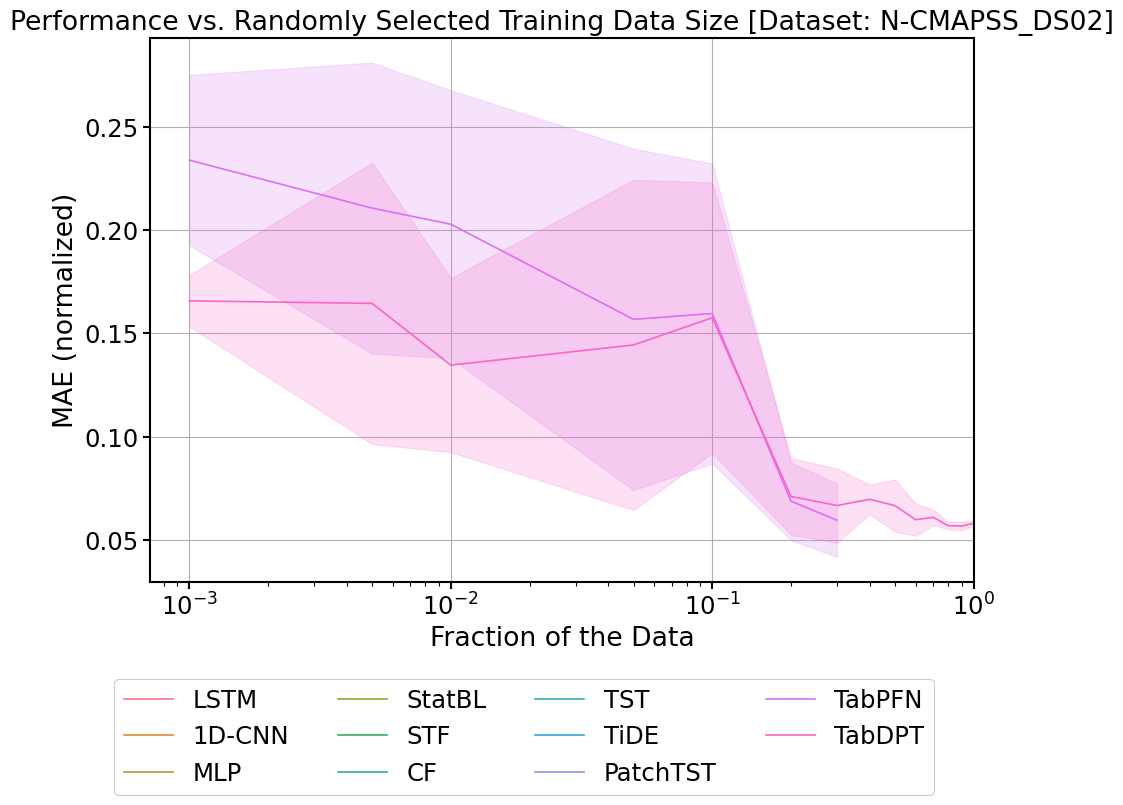

In [27]:
from matplotlib import pyplot as plt
with sns.plotting_context("paper", font_scale=2, rc={"font.family": "Helvetica"}):
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10,7))    



    variable_rename = {
        'lmetk.baselines.lstm_model.LSTM_Forecaster': "LSTM",
        'lmetk.model.wrappers.cnn1d_wrapper.CNN1D_Wrapper': "1D-CNN",
        'lmetk.model.wrappers.mlp_wrapper.MLPWrapper': "MLP",
        'lmetk.model.wrappers.statistical_models_wrapper.StatisticalBaselineWrapper': "StatBL",
        'lmetk.baselines.spacetimeformer_model.Spacetimeformer_Forecaster': "STF",
        'lmetk.baselines.crossformer_model.Crossformer_Forecaster': "CF",
        'lmetk.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster': "TST",
        'lmetk.baselines.tide_model.TiDE_Forecaster': "TiDE",
        'lmetk.baselines.patchtst_model.PatchTST_Forecaster': "PatchTST",
        'lmetk.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper': "TabPFN",
        'lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper': "TabDPT",
    }
    variable_rename = {
        'picid.baselines.lstm_model.LSTM_Forecaster': "LSTM",
        'picid.model.wrappers.cnn1d_wrapper.CNN1D_Wrapper': "1D-CNN",
        'picid.model.wrappers.mlp_wrapper.MLPWrapper': "MLP",
        'picid.model.wrappers.statistical_models_wrapper.StatisticalBaselineWrapper': "StatBL",
        'picid.baselines.spacetimeformer_model.Spacetimeformer_Forecaster': "STF",
        'picid.baselines.crossformer_model.Crossformer_Forecaster': "CF",
        'picid.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster': "TST",
        'picid.baselines.tide_model.TiDE_Forecaster': "TiDE",
        'picid.baselines.patchtst_model.PatchTST_Forecaster': "PatchTST",
        'picid.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper': "TabPFN",
        'picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper': "TabDPT"
    }




    if "n_cmapss_ds02" in PROJECT_NAME:
        plot_df = df_long
        dataset_name = "N-CMAPSS_DS02"
        metric = "test/mae_normalized"
        y_label = "MAE (normalized)"
    elif "n_cmapss" in PROJECT_NAME:
        plot_df = df_long[df_long["ds"] == df_long["ds"].unique()[1]]
        dataset_name = "N-CMAPSS"
        metric = "test/rmse_denormalized"
        y_label = "RMSE (denormalized)"
    elif "phme20" in PROJECT_NAME:
        plot_df = df_long
        dataset_name = "PHME20"
        metric = "test/mae_normalized"
        y_label = "MAE (normalized)"
    elif "mzvav" in PROJECT_NAME:
        dataset_name = "MZVAV"
        plot_df = df_long
        metric = "test/f1"
        y_label = "F1 Score"
    elif "unibo" in PROJECT_NAME:
        dataset_name = "Unibo"
        plot_df = df_long
        metric = "test/mae_normalized"
        y_label = "MAE (normalized)"
    else:
        raise ValueError("Unknown project for plotting")

    # plot_df.to_csv("scaling_laws_railway_mape.csv", index=False)

    def extract_handles_labels_title(ax):
        old_legend = ax.legend_
        handles = old_legend.legend_handles
        labels = [t.get_text() for t in old_legend.get_texts()]
        title = old_legend.get_title().get_text()
        old_legend.remove()
        return handles, labels, title
        # ax.legend(handles, labels, loc=new_loc, title=title, **kws)


    # dashes = {m: (2, 2) if m in ["cf-plan", "stf-plan", "tf-plan", "tide-plan"] else "" for m in ccdfs.variable.unique()}


    sns.lineplot(plot_df[plot_df["model._target_"].isin(
                variable_rename.keys()) & (plot_df["metric"] == metric)],
                x="task_definition.subset_ratio", y="value", hue="model._target_",
                hue_order=list(variable_rename.keys()),
                errorbar="sd"
                #  palette=palette, ax=ax, dashes=dashes, style="variable", alpha=1
                )
    # ax.set_yscale('log')

    # ax.set_title(f"Performance vs. Randomly Selected Training Data Size (%) {PROJECT_NAME}")
    ax.set_title(f"Performance vs. Randomly Selected Training Data Size [Dataset: {dataset_name}]")
    ax.set_ylabel(metric)
    ax.set_xlabel("Fraction of the Data")
    # ax.set_yscale('log')
    ax.set_xscale('log')
    ax.set_axisbelow(True)
    ax.set_xlim(0.0, 1.0)
    ax.grid()


    # Add a box around the plot
    for spine in ax.spines.values():
        spine.set_visible(True)  # Make all spines visible
        spine.set_linewidth(1.5)  # Adjust the box line width if needed
        spine.set_color('black')      # Set the color of the frame

    # Set tick indicators (tick marks) thickness to 1.5
    ax.tick_params(axis='x', width=1.5)  # X-axis tick indicators
    ax.tick_params(axis='y', width=1.5)  # Y-axis tick indicators

    ax.set_ylabel(y_label)

    handles, labels, title = extract_handles_labels_title(ax)   
    labels = [variable_rename[l] for l in labels]

    legend = fig.legend(
    handles=handles, 
    labels=labels, 
    title='', 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.02), 
    ncol=4, 
    framealpha=1,
    )

    fig.tight_layout()
    
    fig.savefig(f'picid_report_artifacts/scaling_laws_{dataset_name}_{metric.split("/")[1]}.pdf', 
                dpi=300, transparent=True, bbox_extra_artists=(legend,), bbox_inches='tight')

In [29]:
plot_df[plot_df["model._target_"] == "picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabPFNWrapper"]

,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value


In [28]:
for key in all_results.keys():
    print(f"Dataset key: {key}")
    for key_2 in all_results[key].keys():
        print(f"  Model key: {key_2}")
        for sub_key in all_results[key][key_2].keys():
            #if pd data frame then display the head only
            if isinstance(all_results[key][key_2][sub_key], pd.DataFrame):
                print(f"    {sub_key}:")
                display(all_results[key][key_2][sub_key].head(2))
            # if dict proceed with keys 
            elif isinstance(all_results[key][key_2][sub_key], dict):
                # same for inside dict and repeat
                for inner_key in all_results[key][key_2][sub_key].keys():
                    # print the 
                    if isinstance(all_results[key][key_2][sub_key][inner_key], pd.DataFrame):
                        print(f"   {sub_key}   {inner_key}:")
                        display(all_results[key][key_2][sub_key][inner_key].head(2))
                    else:
                        print(f" {sub_key}     {inner_key}: {all_results[key][key_2][sub_key][inner_key]}")
                
            else:
                print(f"    {sub_key}: {all_results[key][key_2][sub_key]}")
            
            


Dataset key: MultiSource_concepts_N-CMAPSS
  Model key: picid.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper
 best_hyperparameters     task_definition.subset_ratio: 0.3
 best_hyperparameters     run_names: 0.3+concepts_n_cmapss_ds02+prognostics+tabpfn_fit_predict_f77a4688
 best_performance     optimized_on: {'metric': 'test/mae_denormalized', 'strategy': 'min'}
 best_performance     metrics: defaultdict(<class 'dict'>, {'nasa_score_denormalized': {'test': {'mean': 1.0988814979791641, 'std': 0.6117640730960882, 'count': 4}}, 'mae_normalized': {'test': {'mean': 0.05962382350116968, 'std': 0.017787044291733313, 'count': 4}}, 'loss': {'test': {'mean': 1.0, 'std': 0.0, 'count': 4}}, 'mse_normalized': {'test': {'mean': 0.006487016915343702, 'std': 0.003389313526062162, 'count': 4}}, 'mse_denormalized': {'test': {'mean': 64.87017059326172, 'std': 33.89313111946604, 'count': 4}}, 'nasa_score_normalized': {'test': {'mean': 0.005684467207174748, 'std': 0.001952329716923606, 'c

,_runtime,_step,_timestamp,epoch,test/loss,test/mae_denormalized,test/mae_normalized,test/mse_denormalized,test/mse_normalized,test/nasa_score_denormalized,test/nasa_score_normalized,test/rmse_denormalized,test/rmse_normalized,train/loss_epoch,trainer/global_step,val/loss,val/mae_denormalized,val/mae_normalized,val/mse_denormalized,val/mse_normalized,val/nasa_score_denormalized,val/nasa_score_normalized,val/rmse_denormalized,val/rmse_normalized,loss,seed,tags,test,train,exp_name,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,subset_seed,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,optimization.lr,optimization.optimizer.lr,optimization.optimizer._target_,optimization.optimizer.weight_decay,optimization.scheduler.gamma,optimization.scheduler._target_,optimization.scheduler.step_size,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.load_arguments.concepts,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.test1.RUL,datasource.test1.mode,datasource.test1.n_DS,datasource.test1.path,datasource.test1.cruise,datasource.test1.stride,datasource.test1.scaling,datasource.test1._target_,datasource.test1.concepts,datasource.test1.data_name,datasource.test1.task_mode,datasource.test1.data_folder,datasource.test1.window_size,datasource.test1.group_by_unit,datasource.test1.load_arguments.mode,datasource.test1.load_arguments.n_DS,datasource.test1.load_arguments.units,datasource.test1.load_arguments.concepts,datasource.test1.binary_concepts,datasource.test1.include_healthy,datasource.test1.subsampling_rate,datasource.test1.combined_concepts,datasource.train1.RUL,datasource.train1.mode,datasource.train1.n_DS,datasource.train1.path,datasource.train1.cruise,datasource.train1.stride,datasource.train1.scaling,datasource.train1._target_,datasource.train1.concepts,datasource.train1.data_name,datasource.train1.task_mode,datasource.train1.data_folder,datasource.train1.window_size,datasource.train1.group_by_unit,datasource.train1.load_arguments.mode,datasource.train1.load_arguments.n_DS,datasource.train1.load_arguments.units,datasource.train1.load_arguments.concepts,datasource.train1.binary_concepts,datasource.train1.include_healthy,datasource.train1.subsampling_rate,datasource.train1.combined_concepts,datasource.source_list.val1.RUL,datasource.source_list.val1.mode,datasource.source_list.val1.n_DS,datasource.source_list.val1.path,datasource.source_list.val1.cruise,datasource.source_list.val1.stride,datasource.source_list.val1.scaling,datasource.source_list.val1._target_,datasource.source_list.val1.concepts,datasource.source_list.val1.data_name,datasource.source_list.val1.task_mode,datasource.source_list.val1.data_folder,datasource.source_list.val1.window_size,datasource.source_list.val1.group_by_unit,datasource.source_list.val1.load_arguments.mode,datasource.source_list.val1.load_arguments.n_DS,datasource.source_list.val1.load_arguments.units,datasource.source_list.val1.load_arguments.concepts,datasource.source_list.val1.binary_concepts,datasource.source_list.val1.include_healthy,datasource.source_list.val1.subsampling_rate,datasource.source_list.val1.combined_concepts,datasource.source_list.test1.RUL,datasource.source_list.test1.mode,datasource.source_list.test1.n_DS,datasource.source_l

    total_runs: 28
    configs_failed_not_full_seed_set: 0
    configs_failed_missing_invalid_metric: 0
    sort_metric_used: None
 seeds_info     data: ?
 seeds_info     model: [72, 88, 101, 666]
    diagnostics_log: ['', '============================================================', 'Dataset: MultiSource_concepts_N-CMAPSS  |  Model: picid.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper', '============================================================', '  Optimization metric: test/mae_denormalized  (mode: min)', '  Sort metric used:    test/mae_denormalized', '  Grid source:         auto', '', '  Required seeds:', '    Data:  not required', '    Model: not required', '  Seeds found in data:', '    Data:  ?', '    Model: [72, 88, 101, 666]', '', '  Counts:', '    Configs completed (used for reporting): 4', '    Total runs (rows after filters):      28', '    Configs failed (not full seed set):   0', '    Configs failed (missing/invalid metric): 0', '', '  What the fai

,_runtime,_step,_timestamp,epoch,test/loss,test/mae_denormalized,test/mae_normalized,test/mse_denormalized,test/mse_normalized,test/nasa_score_denormalized,test/nasa_score_normalized,test/rmse_denormalized,test/rmse_normalized,train/loss_epoch,trainer/global_step,val/loss,val/mae_denormalized,val/mae_normalized,val/mse_denormalized,val/mse_normalized,val/nasa_score_denormalized,val/nasa_score_normalized,val/rmse_denormalized,val/rmse_normalized,loss,seed,tags,test,train,exp_name,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,subset_seed,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,optimization.lr,optimization.optimizer.lr,optimization.optimizer._target_,optimization.optimizer.weight_decay,optimization.scheduler.gamma,optimization.scheduler._target_,optimization.scheduler.step_size,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.load_arguments.concepts,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.test1.RUL,datasource.test1.mode,datasource.test1.n_DS,datasource.test1.path,datasource.test1.cruise,datasource.test1.stride,datasource.test1.scaling,datasource.test1._target_,datasource.test1.concepts,datasource.test1.data_name,datasource.test1.task_mode,datasource.test1.data_folder,datasource.test1.window_size,datasource.test1.group_by_unit,datasource.test1.load_arguments.mode,datasource.test1.load_arguments.n_DS,datasource.test1.load_arguments.units,datasource.test1.load_arguments.concepts,datasource.test1.binary_concepts,datasource.test1.include_healthy,datasource.test1.subsampling_rate,datasource.test1.combined_concepts,datasource.train1.RUL,datasource.train1.mode,datasource.train1.n_DS,datasource.train1.path,datasource.train1.cruise,datasource.train1.stride,datasource.train1.scaling,datasource.train1._target_,datasource.train1.concepts,datasource.train1.data_name,datasource.train1.task_mode,datasource.train1.data_folder,datasource.train1.window_size,datasource.train1.group_by_unit,datasource.train1.load_arguments.mode,datasource.train1.load_arguments.n_DS,datasource.train1.load_arguments.units,datasource.train1.load_arguments.concepts,datasource.train1.binary_concepts,datasource.train1.include_healthy,datasource.train1.subsampling_rate,datasource.train1.combined_concepts,datasource.source_list.val1.RUL,datasource.source_list.val1.mode,datasource.source_list.val1.n_DS,datasource.source_list.val1.path,datasource.source_list.val1.cruise,datasource.source_list.val1.stride,datasource.source_list.val1.scaling,datasource.source_list.val1._target_,datasource.source_list.val1.concepts,datasource.source_list.val1.data_name,datasource.source_list.val1.task_mode,datasource.source_list.val1.data_folder,datasource.source_list.val1.window_size,datasource.source_list.val1.group_by_unit,datasource.source_list.val1.load_arguments.mode,datasource.source_list.val1.load_arguments.n_DS,datasource.source_list.val1.load_arguments.units,datasource.source_list.val1.load_arguments.concepts,datasource.source_list.val1.binary_concepts,datasource.source_list.val1.include_healthy,datasource.source_list.val1.subsampling_rate,datasource.source_list.val1.combined_concepts,datasource.source_list.test1.RUL,datasource.source_list.test1.mode,datasource.source_list.test1.n_DS,datasource.source_l

    total_runs: 56
    configs_failed_not_full_seed_set: 0
    configs_failed_missing_invalid_metric: 0
    sort_metric_used: None
 seeds_info     data: ?
 seeds_info     model: [72, 88, 101, 666]
    diagnostics_log: ['', '============================================================', 'Dataset: MultiSource_concepts_N-CMAPSS  |  Model: picid.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper', '============================================================', '  Optimization metric: test/mae_denormalized  (mode: min)', '  Sort metric used:    test/mae_denormalized', '  Grid source:         auto', '', '  Required seeds:', '    Data:  not required', '    Model: not required', '  Seeds found in data:', '    Data:  ?', '    Model: [72, 88, 101, 666]', '', '  Counts:', '    Configs completed (used for reporting): 4', '    Total runs (rows after filters):      56', '    Configs failed (not full seed set):   0', '    Configs failed (missing/invalid metric): 0', '', '  What the fai

In [4]:
display(all_results[key][key_2]['sorted_aggregated_results'])

Model                    model.kernels                   model.strides                 model.dilations                     model.output_channels  \
                                                                                                                                                                                                  
0  picid.model.autoencoder.wrapper.AutoencoderWra...                  (5, 5, 5, 5, 5)                 (1, 1, 1, 1, 1)                 (1, 2, 4, 8, 1)                      (16, 32, 64, 64, 64)   
2  picid.model.autoencoder.wrapper.AutoencoderWra...  (10, 7, 7, 7, 7, 7, 7, 7, 7, 7)  (1, 1, 1, 1, 1, 1, 1, 1, 1, 1)  (1, 1, 1, 1, 1, 1, 1, 1, 1, 1)  (16, 32, 64, 64, 64, 16, 32, 64, 64, 64)   
1  picid.model.autoencoder.wrapper.AutoencoderWra...                  (7, 7, 5, 5, 5)                 (2, 2, 1, 1, 1)                 (1, 1, 1, 1, 1)                      (16, 32, 64, 64, 64)   

   val/loss       val/mse       val/mae      val/rmse     test/loss      test/mse      test/mae     test/rmse                                               run_name  
       mean std      mean std      mean std      mean std      mean std      mean std      mean std      mean std                                               list  
0  0.000058 NaN  0.000058 NaN  0.004978 NaN  0.007645 NaN  0.000058 NaN  0.000058 NaN  0.004978 NaN  0.007645 NaN  [pronostia+reconstruction+residual_autoencoder...  
2  0.000063 NaN  0.000063 NaN  0.005087 NaN  0.007926 NaN  0.000063 NaN  0.000063 NaN  0.005087 NaN  0.007926 NaN  [pronostia+reconstruction+residual_autoencoder...  
1  0.000082 NaN  0.000082 NaN  0.005265 NaN  0.009032 NaN  0.000082 NaN  0.000082 NaN  0.005265 NaN  0.009032 NaN  [pronostia+reconstruction+residual_autoencoder...

In [ ]:
for i in all_results[key][key_2]['non_aggregated_df']['callbacks.model_checkpoint.dirpath']:
    print(str(i))
    

/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_03-30-38/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_03-30-47/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_11-49-26/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_12-25-24/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_20-06-41/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_21-16-34/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-03_04-29-43/checkpoints/checkpoints
/home/levtel/project

In [45]:
all_results[key][key_2]['non_aggregated_df']

,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,train/loss_step,trainer/global_step,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,model/params/trainable,run_name,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,plots/test/reconstructions_overview,plots/train/reconstructions_overview,plots/val/reconstructions_overview,test/loss,test/mae,test/mse,test/rmse,train/loss_epoch,train/mae,train/mse,train/rmse,val/loss,val/mae,val/mse,val/rmse,num_threads,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_dir,datasource.data_name,datasource.task_mode,datasource.fold,datasource.cache_dir,task_definition.stride,task_definition.seq_len,task_definition.pred_len,task_definition.label_len,task_definition.task_type,task_definition.requires_training,task_definition.model.data_requirements.input_tensors,model.kernels,model.strides,model._target_,model.dilations,model.latent_dim,model.dropout_prob,model.input_seq_len,model.input_channels,model.output_channels,model.blocks_config,dataset._target_,dataset._recursive_,dataset.dataset_cfg.stride,dataset.dataset_cfg.seq_len,dataset.dataset_cfg._target_,dataset.dataset_cfg.pred_len,dataset.dataset_cfg.label_len,datamodule._target_,datamodule.num_workers,datamodule.shuffle_val,datamodule.shuffle_test,datamodule.shuffle_train,datamodule.val_batch_size,datamodule.prefetch_factor,datamodule.test_batch_size,datamodule.train_batch_size,callbacks.model_timer._target_,callbacks.model_summary._target_,callbacks.model_summary.max_depth,callbacks.early_stopping.mode,callbacks.early_stopping.strict,callbacks.early_stopping.monitor,callbacks.early_stopping.verbose,callbacks.early_stopping._target_,callbacks.early_stopping.patience,callbacks.early_stopping.min_delta,callbacks.early_stopping.check_finite,callbacks.model_checkpoint.mode,callbacks.model_checkpoint.dirpath,callbacks.model_checkpoint.monitor,callbacks.model_checkpoint.verbose,callbacks.model_checkpoint._target_,callbacks.model_checkpoint.filename,callbacks.model_checkpoint.save_last,callbacks.model_checkpoint.save_top_k,callbacks.model_checkpoint.save_weights_only,callbacks.model_checkpoint.auto_insert_metric_name,callbacks.learning_rate_monitor._target_,callbacks.learning_rate_monitor.logging_interval,Model
52,29813,31573,1.759431e+09,{'runtime': 29813},20,0.00500,6.167217e-05,1573580,{'_target_': 'picid.loss.default.MSELoss'},42,[dev],True,"{'use_cache_after_loading': True, 'use_cache_a...",True,{'wandb': {'id': 'pronostia+reconstruction+res...,"{'devices': [1], '_target_': 'lightning.pytorc...",pronostia/reconstruction/residual_autoencoder,{'val': {'paths': {'log_dir': '/home/levtel/pr...,"{'job': {'id': '???', 'num': '???', 'name': '$...",True,{'scaler_features': {'metadata': {'fit_on': 't...,4,False,False,True,1024,10,1024,debug,128,True,183208,183208,pronostia+reconstruction+residual_autoencoder_...,0.015844,0.003353,1487.310064,21.117129,0.006290,0.001688,67.621402,2.877372,"{'_type': 'plotly-file', 'path': 'media/plotly...","{'_type': 'plotly-file', 'path': 'media/plotly...","{'_type': 'plotly-file', 'path': 'media/plotly...",1.429764e-04,0.007379,2.859528e-04,0.011957,6.198527e-02,0.012541,1.239705e-01,2.489684e-01,1.429764e-04,0.007379,2.859528e-04,0.011957,NaN,picid.optimizer.default.DefaultOptimizer,Adam,StepLR,0.5,10,0.0100,0,picid.data.datasources.phmd_pronostia.Pronosti...,NaN,PRONOSTIA,rul,0.0,/home/levtel/projects/TabPHM/datasets/phmd_cache,1,64,0,0,reconstruction,True,[features]

In [36]:
# If run_name is the first element in the tuple
